In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Download the SECOM semiconductor dataset
secom = fetch_ucirepo(id=179)

# Separate features and target
X = secom.data.features
y = secom.data.targets

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print(secom.data)

{'ids': None, 'features': None, 'targets': None, 'original':       class            timestamp  Attribute 1  Attribute 2  Attribute 3  \
0        -1  19/07/2008 11:55:00      3030.93      2564.00    2187.7333   
1        -1  19/07/2008 12:32:00      3095.78      2465.14    2230.4222   
2         1  19/07/2008 13:17:00      2932.61      2559.94    2186.4111   
3        -1  19/07/2008 14:43:00      2988.72      2479.90    2199.0333   
4        -1  19/07/2008 15:22:00      3032.24      2502.87    2233.3667   
...     ...                  ...          ...          ...          ...   
1562     -1  16/10/2008 15:13:00      2899.41      2464.36    2179.7333   
1563     -1  16/10/2008 20:49:00      3052.31      2522.55    2198.5667   
1564     -1  17/10/2008 05:26:00      2978.81      2379.78    2206.3000   
1565     -1  17/10/2008 06:01:00      2894.92      2532.01    2177.0333   
1566     -1  17/10/2008 06:07:00      2944.92      2450.76    2195.4444   

      Attribute 4  Attribute 5  Attrib

In [5]:
print(secom.variables.tail(10))

Empty DataFrame
Columns: []
Index: []


In [6]:
# Get the complete SECOM dataframe
df = secom.data.original.copy()

print("Original dataset shape:", df.shape)
df.head()

Original dataset shape: (1567, 592)


,class,timestamp,Attribute 1,Attribute 2,Attribute 3,Attribute 4,Attribute 5,Attribute 6,Attribute 7,Attribute 8,...,Attribute 581,Attribute 582,Attribute 583,Attribute 584,Attribute 585,Attribute 586,Attribute 587,Attribute 588,Attribute 589,Attribute 590
0,-1,19/07/2008 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,-1,19/07/2008 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,1,19/07/2008 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,-1,19/07/2008 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,-1,19/07/2008 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [7]:
# Target: PASS / FAIL
y = df["class"]

# Process measurements only
# We remove 'class' because it is the answer we want to predict
# We remove 'timestamp' because it is not a process sensor measurement
X = df.drop(columns=["class", "timestamp"])

print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)

Feature dataset shape: (1567, 590)
Target shape: (1567,)


In [8]:
print(y.value_counts())

class
-1    1463
 1     104
Name: count, dtype: int64


In [9]:
print("PASS:", (y == -1).sum())
print("FAIL:", (y == 1).sum())

PASS: 1463
FAIL: 104


In [10]:
X.head()

,Attribute 1,Attribute 2,Attribute 3,Attribute 4,Attribute 5,Attribute 6,Attribute 7,Attribute 8,Attribute 9,Attribute 10,...,Attribute 581,Attribute 582,Attribute 583,Attribute 584,Attribute 585,Attribute 586,Attribute 587,Attribute 588,Attribute 589,Attribute 590
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [11]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 590 entries, Attribute 1 to Attribute 590
dtypes: float64(590)
memory usage: 7.1 MB


In [12]:
total_missing = X.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 41951


In [13]:
missing_per_feature = X.isnull().sum()

missing_per_feature.sort_values(ascending=False).head(20)

Attribute 293    1429
Attribute 294    1429
Attribute 159    1429
Attribute 158    1429
Attribute 493    1341
Attribute 86     1341
Attribute 359    1341
Attribute 221    1341
Attribute 245    1018
Attribute 518    1018
Attribute 110    1018
Attribute 247    1018
Attribute 384    1018
Attribute 383    1018
Attribute 385    1018
Attribute 246    1018
Attribute 112    1018
Attribute 111    1018
Attribute 517    1018
Attribute 519    1018
dtype: int64

In [14]:
missing_percentage = X.isnull().mean() * 100

missing_percentage.sort_values(ascending=False).head(20)

Attribute 293    91.193363
Attribute 294    91.193363
Attribute 159    91.193363
Attribute 158    91.193363
Attribute 493    85.577537
Attribute 86     85.577537
Attribute 359    85.577537
Attribute 221    85.577537
Attribute 245    64.964901
Attribute 518    64.964901
Attribute 110    64.964901
Attribute 247    64.964901
Attribute 384    64.964901
Attribute 383    64.964901
Attribute 385    64.964901
Attribute 246    64.964901
Attribute 112    64.964901
Attribute 111    64.964901
Attribute 517    64.964901
Attribute 519    64.964901
dtype: float64

In [15]:
unique_values = X.nunique()

constant_features = unique_values[unique_values <= 1]

print("Number of constant features:", len(constant_features))

Number of constant features: 116


In [16]:
constant_features

Attribute 6      1
Attribute 14     1
Attribute 43     1
Attribute 50     1
Attribute 53     1
                ..
Attribute 535    1
Attribute 536    1
Attribute 537    1
Attribute 538    1
Attribute 539    1
Length: 116, dtype: int64

In [17]:
X.describe()

,Attribute 1,Attribute 2,Attribute 3,Attribute 4,Attribute 5,Attribute 6,Attribute 7,Attribute 8,Attribute 9,Attribute 10,...,Attribute 581,Attribute 582,Attribute 583,Attribute 584,Attribute 585,Attribute 586,Attribute 587,Attribute 588,Attribute 589,Attribute 590
count,1561.000000,1560.000000,1553.000000,1553.000000,1553.000000,1553.0,1553.000000,1558.000000,1565.000000,1565.000000,...,618.000000,618.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000
mean,3014.452896,2495.850231,2200.547318,1396.376627,4.197013,100.0,101.112908,0.121822,1.462862,-0.000841,...,0.005396,97.934373,0.500096,0.015318,0.003847,3.067826,0.021458,0.016475,0.005283,99.670066
std,73.621787,80.407705,29.513152,441.691640,56.355540,0.0,6.237214,0.008961,0.073897,0.015116,...,0.003116,87.520966,0.003404,0.017180,0.003720,3.578033,0.012358,0.008808,0.002867,93.891919
min,2743.240000,2158.750000,2060.660000,0.000000,0.681500,100.0,82.131100,0.000000,1.191000,-0.053400,...,0.001000,0.000000,0.477800,0.006000,0.001700,1.197500,-0.016900,0.003200,0.001000,0.000000
25%,2966.260000,2452.247500,2181.044400,1081.875800,1.017700,100.0,97.920000,0.121100,1.411200,-0.010800,...,0.003400,46.184900,0.497900,0.011600,0.003100,2.306500,0.013425,0.010600,0.003300,44.368600
50%,3011.490000,2499.405000,2201.066700,1285.214400,1.316800,100.0,101.512200,0.122400,1.461600,-0.001300,...,0.004700,72.288900,0.500200,0.013800,0.003600,2.757650,0.020500,0.014800,0.004600,71.900500
75%,3056.650000,2538.822500,2218.055500,1591.223500,1.525700,100.0,104.586700,0.123800,1.516900,0.008400,...,0.006475,116.539150,0.502375,0.016500,0.004100,3.295175,0.027600,0.020300,0.006400,114.749700
max,3356.350000,2846.440000,2315.266700,3715.041700,1114.536600,100.0,129.252200,0.128600,1.656400,0.074900,...,0.028600,737.304800,0.509800,0.476600,0.104500,99.303200,0.102800,0.079900,0.028600,737.304800


In [18]:
print("=" * 50)
print("SECOM SEMICONDUCTOR DATASET SUMMARY")
print("=" * 50)

print(f"Samples:              {X.shape[0]}")
print(f"Process features:     {X.shape[1]}")
print(f"PASS samples:         {(y == -1).sum()}")
print(f"FAIL samples:         {(y == 1).sum()}")
print(f"Failure rate:         {(y == 1).mean() * 100:.2f}%")
print(f"Missing values:       {X.isnull().sum().sum()}")
print(f"Constant features:    {(X.nunique() <= 1).sum()}")

SECOM SEMICONDUCTOR DATASET SUMMARY
Samples:              1567
Process features:     590
PASS samples:         1463
FAIL samples:         104
Failure rate:         6.64%
Missing values:       41951
Constant features:    116


In [19]:
X_clean = X.copy()
y_clean = y.copy()

print("Starting shape:", X_clean.shape)

Starting shape: (1567, 590)


In [20]:
constant_columns = X_clean.columns[X_clean.nunique() <= 1]

print("Constant features to remove:", len(constant_columns))

Constant features to remove: 116


In [21]:
X_clean = X_clean.drop(columns=constant_columns)

print("Shape after removing constant features:")
print(X_clean.shape)

Shape after removing constant features:
(1567, 474)


In [22]:
missing_percentage = X_clean.isnull().mean() * 100

high_missing_columns = missing_percentage[
    missing_percentage > 50
].index

print("Features with more than 50% missing:")
print(len(high_missing_columns))

Features with more than 50% missing:
28


In [23]:
missing_percentage[
    missing_percentage > 50
].sort_values(ascending=False)

Attribute 158    91.193363
Attribute 159    91.193363
Attribute 294    91.193363
Attribute 293    91.193363
Attribute 493    85.577537
Attribute 359    85.577537
Attribute 86     85.577537
Attribute 221    85.577537
Attribute 111    64.964901
Attribute 245    64.964901
Attribute 110    64.964901
Attribute 112    64.964901
Attribute 518    64.964901
Attribute 519    64.964901
Attribute 247    64.964901
Attribute 246    64.964901
Attribute 384    64.964901
Attribute 385    64.964901
Attribute 517    64.964901
Attribute 383    64.964901
Attribute 581    60.561583
Attribute 582    60.561583
Attribute 579    60.561583
Attribute 580    60.561583
Attribute 74     50.670070
Attribute 73     50.670070
Attribute 346    50.670070
Attribute 347    50.670070
dtype: float64

In [24]:
X_clean = X_clean.drop(columns=high_missing_columns)

print("Shape after removing high-missing features:")
print(X_clean.shape)

Shape after removing high-missing features:
(1567, 446)


In [25]:
print("Remaining missing values:")
print(X_clean.isnull().sum().sum())

Remaining missing values:
10868


In [26]:
X_clean = X_clean.fillna(X_clean.median())

In [27]:
from sklearn.model_selection import train_test_split

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

In [29]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1253, 446)
X_test : (314, 446)
y_train: (1253,)
y_test : (314,)


In [32]:
stratify=y_clean

In [33]:
print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
class
-1    93.375898
 1     6.624102
Name: proportion, dtype: float64

Testing distribution:
class
-1    93.312102
 1     6.687898
Name: proportion, dtype: float64


In [34]:
from sklearn.impute import SimpleImputer

In [35]:
imputer = SimpleImputer(strategy="median")

In [36]:
X_train_imputed = imputer.fit_transform(X_train)

In [37]:
X_test_imputed = imputer.transform(X_test)

In [38]:
import numpy as np

print("Training missing values:")
print(np.isnan(X_train_imputed).sum())

print("Testing missing values:")
print(np.isnan(X_test_imputed).sum())

Training missing values:
0
Testing missing values:
0


In [39]:
from sklearn.preprocessing import StandardScaler

In [40]:
scaler = StandardScaler()

In [41]:
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [42]:
print("Mean of scaled training data:")
print(X_train_scaled.mean())

print("\nStandard deviation:")
print(X_train_scaled.std())

Mean of scaled training data:
-5.127181011227948e-18

Standard deviation:
1.0


In [43]:
print("=" * 55)
print("SECOM DATA CLEANING SUMMARY")
print("=" * 55)

print(f"Original features:          {X.shape[1]}")
print(f"Constant features removed: {len(constant_columns)}")
print(f"High-missing removed:      {len(high_missing_columns)}")
print(f"Remaining features:        {X_clean.shape[1]}")

print()
print(f"Training samples:          {X_train.shape[0]}")
print(f"Testing samples:           {X_test.shape[0]}")

print()
print(f"Training missing values:   {np.isnan(X_train_imputed).sum()}")
print(f"Testing missing values:    {np.isnan(X_test_imputed).sum()}")

SECOM DATA CLEANING SUMMARY
Original features:          590
Constant features removed: 116
High-missing removed:      28
Remaining features:        446

Training samples:          1253
Testing samples:           314

Training missing values:   0
Testing missing values:    0


In [44]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_scaled, y_train)

dummy_pred = dummy_model.predict(X_test_scaled)

print("Dummy Model Accuracy:")
print(accuracy_score(y_test, dummy_pred))

Dummy Model Accuracy:
0.9331210191082803


In [45]:
print(classification_report(
    y_test,
    dummy_pred,
    labels=[-1, 1],
    target_names=["PASS", "FAIL"],
    zero_division=0
))

              precision    recall  f1-score   support

        PASS       0.93      1.00      0.97       293
        FAIL       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314



In [46]:
from sklearn.linear_model import LogisticRegression

In [47]:
log_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [48]:
log_pred = log_model.predict(X_test_scaled)

In [49]:
print("Logistic Regression Accuracy:")
print(accuracy_score(y_test, log_pred))

Logistic Regression Accuracy:
0.8726114649681529


In [50]:
print(classification_report(
    y_test,
    log_pred,
    labels=[-1, 1],
    target_names=["PASS", "FAIL"],
    zero_division=0
))

              precision    recall  f1-score   support

        PASS       0.94      0.92      0.93       293
        FAIL       0.12      0.14      0.13        21

    accuracy                           0.87       314
   macro avg       0.53      0.53      0.53       314
weighted avg       0.88      0.87      0.88       314



In [51]:
cm = confusion_matrix(
    y_test,
    log_pred,
    labels=[-1, 1]
)

print(cm)

[[271  22]
 [ 18   3]]


In [52]:
tn, fp, fn, tp = cm.ravel()

print("Correct PASS predictions:", tn)
print("False alarms:", fp)
print("Missed FAIL cases:", fn)
print("Correctly detected FAIL cases:", tp)

Correct PASS predictions: 271
False alarms: 22
Missed FAIL cases: 18
Correctly detected FAIL cases: 3


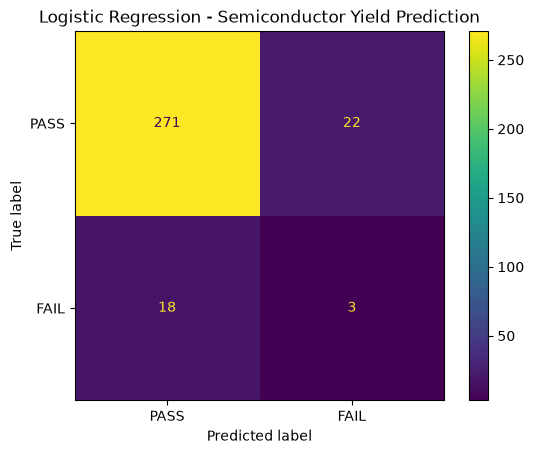

In [53]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["PASS", "FAIL"]
).plot()

plt.title("Logistic Regression - Semiconductor Yield Prediction")
plt.show()

In [54]:
balanced_log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

In [55]:
balanced_log_model.fit(
    X_train_scaled,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [56]:
balanced_log_pred = balanced_log_model.predict(
    X_test_scaled
)

In [57]:
print(classification_report(
    y_test,
    balanced_log_pred,
    labels=[-1, 1],
    target_names=["PASS", "FAIL"],
    zero_division=0
))

              precision    recall  f1-score   support

        PASS       0.94      0.88      0.91       293
        FAIL       0.11      0.19      0.14        21

    accuracy                           0.84       314
   macro avg       0.52      0.54      0.52       314
weighted avg       0.88      0.84      0.86       314



In [58]:
balanced_cm = confusion_matrix(
    y_test,
    balanced_log_pred,
    labels=[-1, 1]
)

tn, fp, fn, tp = balanced_cm.ravel()

print("=== BALANCED LOGISTIC REGRESSION ===")
print("Correct PASS predictions:", tn)
print("False alarms:", fp)
print("Missed FAIL cases:", fn)
print("Correctly detected FAIL cases:", tp)

=== BALANCED LOGISTIC REGRESSION ===
Correct PASS predictions: 259
False alarms: 34
Missed FAIL cases: 17
Correctly detected FAIL cases: 4


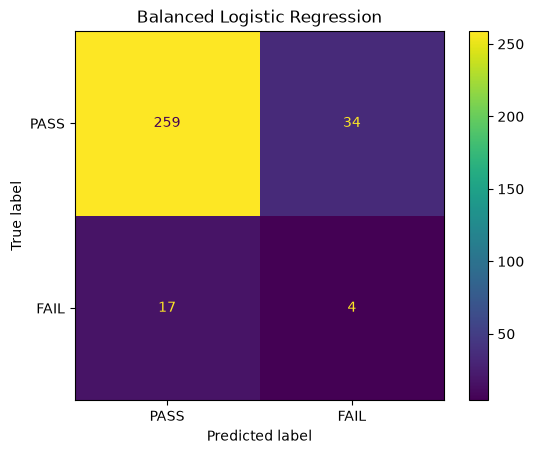

In [59]:
ConfusionMatrixDisplay(
    confusion_matrix=balanced_cm,
    display_labels=["PASS", "FAIL"]
).plot()

plt.title("Balanced Logistic Regression")
plt.show()

In [60]:
from sklearn.metrics import roc_auc_score, average_precision_score

In [61]:
y_test_binary = (y_test == 1).astype(int)

In [62]:
fail_probability = balanced_log_model.predict_proba(
    X_test_scaled
)[:, 1]

In [63]:
roc_auc = roc_auc_score(
    y_test_binary,
    fail_probability
)

pr_auc = average_precision_score(
    y_test_binary,
    fail_probability
)

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC:  {pr_auc:.3f}")

ROC-AUC: 0.621
PR-AUC:  0.150


In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

fail_precision = precision_score(
    y_test,
    balanced_log_pred,
    pos_label=1
)

fail_recall = recall_score(
    y_test,
    balanced_log_pred,
    pos_label=1
)

fail_f1 = f1_score(
    y_test,
    balanced_log_pred,
    pos_label=1
)

accuracy = accuracy_score(
    y_test,
    balanced_log_pred
)

print("=" * 55)
print("SEMICONDUCTOR YIELD PREDICTION - BASELINE MODEL")
print("=" * 55)

print(f"Model:              Balanced Logistic Regression")
print(f"Accuracy:           {accuracy:.3f}")
print(f"FAIL Precision:     {fail_precision:.3f}")
print(f"FAIL Recall:        {fail_recall:.3f}")
print(f"FAIL F1-score:      {fail_f1:.3f}")
print(f"ROC-AUC:            {roc_auc:.3f}")
print(f"PR-AUC:             {pr_auc:.3f}")

print()
print(f"Correct PASS:       {tn}")
print(f"False alarms:       {fp}")
print(f"Missed FAIL:        {fn}")
print(f"Detected FAIL:      {tp}")

SEMICONDUCTOR YIELD PREDICTION - BASELINE MODEL
Model:              Balanced Logistic Regression
Accuracy:           0.838
FAIL Precision:     0.105
FAIL Recall:        0.190
FAIL F1-score:      0.136
ROC-AUC:            0.621
PR-AUC:             0.150

Correct PASS:       259
False alarms:       34
Missed FAIL:        17
Detected FAIL:      4


In [65]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_imputed, y_train)

print("Random Forest training complete!")

Random Forest training complete!


In [66]:
rf_pred = rf_model.predict(X_test_imputed)

In [67]:
print(classification_report(
    y_test,
    rf_pred,
    labels=[-1, 1],
    target_names=["PASS", "FAIL"],
    zero_division=0
))

              precision    recall  f1-score   support

        PASS       0.93      1.00      0.97       293
        FAIL       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314



In [68]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=[-1, 1]
)

tn_rf, fp_rf, fn_rf, tp_rf = rf_cm.ravel()

print("Correct PASS:", tn_rf)
print("False alarms:", fp_rf)
print("Missed FAIL:", fn_rf)
print("Detected FAIL:", tp_rf)

Correct PASS: 293
False alarms: 0
Missed FAIL: 21
Detected FAIL: 0


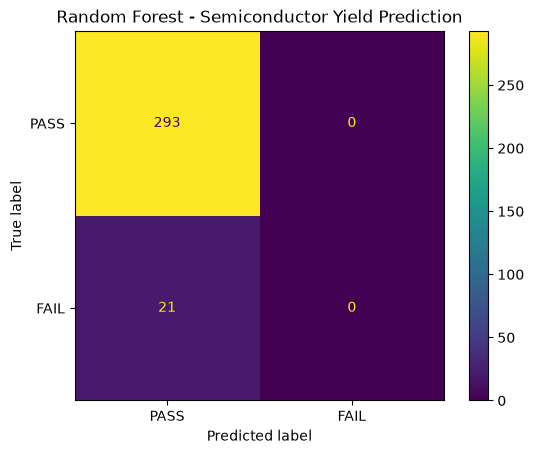

In [69]:
ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["PASS", "FAIL"]
).plot()

plt.title("Random Forest - Semiconductor Yield Prediction")
plt.show()

In [70]:
rf_fail_probability = rf_model.predict_proba(
    X_test_imputed
)[:, 1]

In [71]:
rf_roc_auc = roc_auc_score(
    y_test_binary,
    rf_fail_probability
)

rf_pr_auc = average_precision_score(
    y_test_binary,
    rf_fail_probability
)

print(f"ROC-AUC: {rf_roc_auc:.3f}")
print(f"PR-AUC:  {rf_pr_auc:.3f}")

ROC-AUC: 0.762
PR-AUC:  0.223


In [72]:
rf_precision = precision_score(
    y_test,
    rf_pred,
    pos_label=1,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    pos_label=1,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    pos_label=1,
    zero_division=0
)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("=" * 55)
print("SEMICONDUCTOR YIELD PREDICTION - RANDOM FOREST")
print("=" * 55)

print(f"Accuracy:           {rf_accuracy:.3f}")
print(f"FAIL Precision:     {rf_precision:.3f}")
print(f"FAIL Recall:        {rf_recall:.3f}")
print(f"FAIL F1-score:      {rf_f1:.3f}")
print(f"ROC-AUC:            {rf_roc_auc:.3f}")
print(f"PR-AUC:             {rf_pr_auc:.3f}")

print()
print(f"Correct PASS:       {tn_rf}")
print(f"False alarms:       {fp_rf}")
print(f"Missed FAIL:        {fn_rf}")
print(f"Detected FAIL:      {tp_rf}")

SEMICONDUCTOR YIELD PREDICTION - RANDOM FOREST
Accuracy:           0.933
FAIL Precision:     0.000
FAIL Recall:        0.000
FAIL F1-score:      0.000
ROC-AUC:            0.762
PR-AUC:             0.223

Correct PASS:       293
False alarms:       0
Missed FAIL:        21
Detected FAIL:      0


In [73]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

In [74]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
93,Attribute 104,0.021653
54,Attribute 60,0.015035
31,Attribute 34,0.013178
29,Attribute 32,0.011805
117,Attribute 131,0.010211
59,Attribute 65,0.009300
390,Attribute 520,0.008867
187,Attribute 214,0.008680
60,Attribute 66,0.008577
367,Attribute 478,0.007881


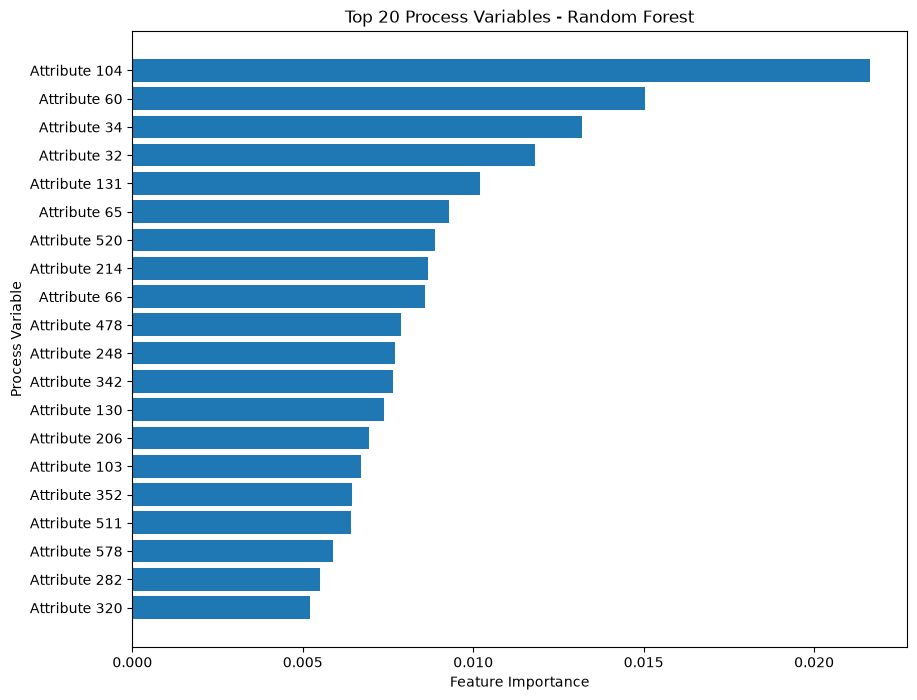

In [75]:
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Process Variable")
plt.title("Top 20 Process Variables - Random Forest")

plt.show()

In [76]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Sub-training:", X_subtrain.shape)
print("Validation:", X_val.shape)

print("\nValidation class distribution:")
print(y_val.value_counts())

Sub-training: (1002, 446)
Validation: (251, 446)

Validation class distribution:
class
-1    234
 1     17
Name: count, dtype: int64


In [77]:
from sklearn.impute import SimpleImputer

rf_imputer = SimpleImputer(strategy="median")

X_subtrain_imputed = rf_imputer.fit_transform(X_subtrain)
X_val_imputed = rf_imputer.transform(X_val)

In [78]:
from sklearn.ensemble import RandomForestClassifier

rf_tune_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_tune_model.fit(
    X_subtrain_imputed,
    y_subtrain
)

print("Random Forest trained.")

Random Forest trained.


In [79]:
fail_class_index = list(rf_tune_model.classes_).index(1)

val_fail_probability = rf_tune_model.predict_proba(
    X_val_imputed
)[:, fail_class_index]

In [80]:
print("Lowest FAIL probability:")
print(val_fail_probability.min())

print("\nHighest FAIL probability:")
print(val_fail_probability.max())

print("\nAverage FAIL probability:")
print(val_fail_probability.mean())

Lowest FAIL probability:
0.009872255489021957

Highest FAIL probability:
0.2481531125204915

Average FAIL probability:
0.07832840322980199


In [81]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    fbeta_score
)

threshold_results = []

for threshold in np.arange(0.05, 0.51, 0.05):

    predictions = np.where(
        val_fail_probability >= threshold,
        1,
        -1
    )

    precision = precision_score(
        y_val,
        predictions,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        pos_label=1,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val,
        predictions,
        beta=2,
        pos_label=1,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "F2": f2
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1,F2
0,0.05,0.094444,1.000000,0.172589,0.342742
1,0.10,0.114754,0.411765,0.179487,0.271318
2,0.15,0.142857,0.117647,0.129032,0.121951
3,0.20,0.200000,0.058824,0.090909,0.068493
4,0.25,0.000000,0.000000,0.000000,0.000000
5,0.30,0.000000,0.000000,0.000000,0.000000
6,0.35,0.000000,0.000000,0.000000,0.000000
7,0.40,0.000000,0.000000,0.000000,0.000000
8,0.45,0.000000,0.000000,0.000000,0.000000
9,0.50,0.000000,0.000000,0.000000,0.000000


In [82]:
threshold_df.sort_values(
    by="F2",
    ascending=False
)

,Threshold,Precision,Recall,F1,F2
0,0.05,0.094444,1.000000,0.172589,0.342742
1,0.10,0.114754,0.411765,0.179487,0.271318
2,0.15,0.142857,0.117647,0.129032,0.121951
3,0.20,0.200000,0.058824,0.090909,0.068493
4,0.25,0.000000,0.000000,0.000000,0.000000
5,0.30,0.000000,0.000000,0.000000,0.000000
6,0.35,0.000000,0.000000,0.000000,0.000000
7,0.40,0.000000,0.000000,0.000000,0.000000
8,0.45,0.000000,0.000000,0.000000,0.000000
9,0.50,0.000000,0.000000,0.000000,0.000000


In [83]:
threshold_results_fine = []

for threshold in np.arange(0.05, 0.151, 0.01):

    predictions = np.where(
        val_fail_probability >= threshold,
        1,
        -1
    )

    precision = precision_score(
        y_val,
        predictions,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        pos_label=1,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val,
        predictions,
        beta=2,
        pos_label=1,
        zero_division=0
    )

    cm_temp = confusion_matrix(
        y_val,
        predictions,
        labels=[-1, 1]
    )

    tn_temp, fp_temp, fn_temp, tp_temp = cm_temp.ravel()

    threshold_results_fine.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "F2": f2,
        "False Alarms": fp_temp,
        "Missed FAIL": fn_temp,
        "Detected FAIL": tp_temp
    })

fine_threshold_df = pd.DataFrame(threshold_results_fine)

fine_threshold_df

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
0,0.05,0.094444,1.000000,0.172589,0.342742,163,0,17
1,0.06,0.104575,0.941176,0.188235,0.361991,137,1,16
2,0.07,0.106557,0.764706,0.187050,0.342105,109,4,13
3,0.08,0.120000,0.705882,0.205128,0.357143,88,5,12
4,0.09,0.121622,0.529412,0.197802,0.316901,65,8,9
5,0.10,0.114754,0.411765,0.179487,0.271318,54,10,7
6,0.11,0.122449,0.352941,0.181818,0.256410,43,11,6
7,0.12,0.108108,0.235294,0.148148,0.190476,33,13,4
8,0.13,0.120000,0.176471,0.142857,0.161290,22,14,3
9,0.14,0.157895,0.176471,0.166667,0.172414,16,14,3


In [84]:
fine_threshold_df.sort_values(
    by="F2",
    ascending=False
)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
1,0.06,0.104575,0.941176,0.188235,0.361991,137,1,16
3,0.08,0.120000,0.705882,0.205128,0.357143,88,5,12
0,0.05,0.094444,1.000000,0.172589,0.342742,163,0,17
2,0.07,0.106557,0.764706,0.187050,0.342105,109,4,13
4,0.09,0.121622,0.529412,0.197802,0.316901,65,8,9
5,0.10,0.114754,0.411765,0.179487,0.271318,54,10,7
6,0.11,0.122449,0.352941,0.181818,0.256410,43,11,6
7,0.12,0.108108,0.235294,0.148148,0.190476,33,13,4
9,0.14,0.157895,0.176471,0.166667,0.172414,16,14,3
8,0.13,0.120000,0.176471,0.142857,0.161290,22,14,3


In [85]:
candidate_thresholds = fine_threshold_df[
    fine_threshold_df["Recall"] >= 0.40
]

candidate_thresholds.sort_values(
    by="False Alarms",
    ascending=True
)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
5,0.10,0.114754,0.411765,0.179487,0.271318,54,10,7
4,0.09,0.121622,0.529412,0.197802,0.316901,65,8,9
3,0.08,0.120000,0.705882,0.205128,0.357143,88,5,12
2,0.07,0.106557,0.764706,0.187050,0.342105,109,4,13
1,0.06,0.104575,0.941176,0.188235,0.361991,137,1,16
0,0.05,0.094444,1.000000,0.172589,0.342742,163,0,17


In [86]:
best_threshold = 0.10

In [87]:
from sklearn.impute import SimpleImputer

final_rf_imputer = SimpleImputer(strategy="median")

X_train_final = final_rf_imputer.fit_transform(X_train)
X_test_final = final_rf_imputer.transform(X_test)

In [88]:
from sklearn.ensemble import RandomForestClassifier

final_rf_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(
    X_train_final,
    y_train
)

print("Final Random Forest trained!")

Final Random Forest trained!


In [89]:
fail_class_index = list(final_rf_model.classes_).index(1)

test_fail_probability = final_rf_model.predict_proba(
    X_test_final
)[:, fail_class_index]

In [90]:
best_threshold = 0.10

final_rf_pred = np.where(
    test_fail_probability >= best_threshold,
    1,
    -1
)

In [91]:
from sklearn.metrics import confusion_matrix

final_rf_cm = confusion_matrix(
    y_test,
    final_rf_pred,
    labels=[-1, 1]
)

tn_final, fp_final, fn_final, tp_final = final_rf_cm.ravel()

print("Correct PASS:", tn_final)
print("False alarms:", fp_final)
print("Missed FAIL:", fn_final)
print("Detected FAIL:", tp_final)

Correct PASS: 248
False alarms: 45
Missed FAIL: 10
Detected FAIL: 11


In [92]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_accuracy = accuracy_score(
    y_test,
    final_rf_pred
)

final_precision = precision_score(
    y_test,
    final_rf_pred,
    pos_label=1,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_rf_pred,
    pos_label=1,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    final_rf_pred,
    pos_label=1,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test_binary,
    test_fail_probability
)

final_pr_auc = average_precision_score(
    y_test_binary,
    test_fail_probability
)

In [93]:
print("=" * 60)
print("SEMICONDUCTOR YIELD PREDICTION - TUNED RANDOM FOREST")
print("=" * 60)

print(f"Decision threshold:   {best_threshold:.2f}")

print()
print(f"Accuracy:             {final_accuracy:.3f}")
print(f"FAIL Precision:       {final_precision:.3f}")
print(f"FAIL Recall:          {final_recall:.3f}")
print(f"FAIL F1-score:        {final_f1:.3f}")
print(f"ROC-AUC:              {final_roc_auc:.3f}")
print(f"PR-AUC:               {final_pr_auc:.3f}")

print()
print(f"Correct PASS:         {tn_final}")
print(f"False alarms:         {fp_final}")
print(f"Missed FAIL:          {fn_final}")
print(f"Detected FAIL:        {tp_final}")
print(f"Total actual FAIL:    {fn_final + tp_final}")

SEMICONDUCTOR YIELD PREDICTION - TUNED RANDOM FOREST
Decision threshold:   0.10

Accuracy:             0.825
FAIL Precision:       0.196
FAIL Recall:          0.524
FAIL F1-score:        0.286
ROC-AUC:              0.769
PR-AUC:               0.193

Correct PASS:         248
False alarms:         45
Missed FAIL:          10
Detected FAIL:        11
Total actual FAIL:    21


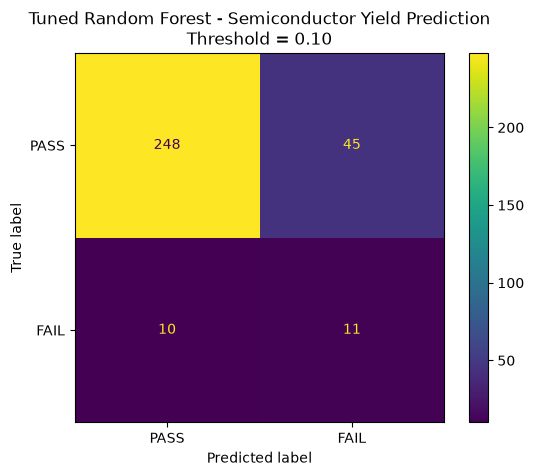

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=final_rf_cm,
    display_labels=["PASS", "FAIL"]
).plot()

plt.title(
    "Tuned Random Forest - Semiconductor Yield Prediction\n"
    "Threshold = 0.10"
)

plt.show()

In [95]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 3.7/48.9 MB 23.4 MB/s eta 0:00:02
   ------- -------------------------------- 8.9/48.9 MB 24.3 MB/s eta 0:00:02
   ------------ --------------------------- 15.5/48.9 MB 26.9 MB/s eta 0:00:02
   ----------------- ---------------------- 21.0/48.9 MB 27.1 MB/s eta 0:00:02
   ----------------------- ---------------- 28.6/48.9 MB 28.9 MB/s eta 0:00:01
   ----------------------------- ---------- 36.2/48.9 MB 30.4 MB/s eta 0:00:01
   ----------------------------------- ---- 43.5/48.9 MB 31.2 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 31.4 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 29.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [100]:
from xgboost import XGBClassifier

In [98]:
y_subtrain_xgb = (y_subtrain == 1).astype(int)
y_val_xgb = (y_val == 1).astype(int)

In [101]:
print(y_subtrain_xgb.value_counts())

class
0    936
1     66
Name: count, dtype: int64


In [102]:
negative_count = (y_subtrain_xgb == 0).sum()
positive_count = (y_subtrain_xgb == 1).sum()

scale_pos_weight = negative_count / positive_count

print("PASS samples:", negative_count)
print("FAIL samples:", positive_count)
print("Scale pos weight:", scale_pos_weight)

PASS samples: 936
FAIL samples: 66
Scale pos weight: 14.181818181818182


In [103]:
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_subtrain_imputed,
    y_subtrain_xgb
)

print("XGBoost training complete!")

XGBoost training complete!


In [104]:
xgb_val_probability = xgb_model.predict_proba(
    X_val_imputed
)[:, 1]

In [105]:
print("Lowest probability:", xgb_val_probability.min())
print("Highest probability:", xgb_val_probability.max())
print("Average probability:", xgb_val_probability.mean())

Lowest probability: 0.00028819538
Highest probability: 0.5960964
Average probability: 0.048329182


In [106]:
xgb_threshold_results = []

for threshold in np.arange(0.05, 0.51, 0.01):

    predictions = (
        xgb_val_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_xgb,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_xgb,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val_xgb,
        predictions,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val_xgb,
        predictions,
        beta=2,
        zero_division=0
    )

    cm = confusion_matrix(
        y_val_xgb,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    xgb_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "F2": f2,
        "False Alarms": fp,
        "Missed FAIL": fn,
        "Detected FAIL": tp
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

In [107]:
xgb_threshold_df.sort_values(
    by="F2",
    ascending=False
).head(15)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
1,0.06,0.100000,0.294118,0.149254,0.211864,45,12,5
7,0.12,0.148148,0.235294,0.181818,0.210526,23,13,4
0,0.05,0.090909,0.294118,0.138889,0.203252,50,12,5
6,0.11,0.129032,0.235294,0.166667,0.202020,27,13,4
5,0.10,0.114286,0.235294,0.153846,0.194175,31,13,4
4,0.09,0.111111,0.235294,0.150943,0.192308,32,13,4
3,0.08,0.097561,0.235294,0.137931,0.183486,37,13,4
2,0.07,0.095238,0.235294,0.135593,0.181818,38,13,4
13,0.18,0.176471,0.176471,0.176471,0.176471,14,14,3
12,0.17,0.150000,0.176471,0.162162,0.170455,17,14,3


In [108]:
xgb_candidates = xgb_threshold_df[
    xgb_threshold_df["Recall"] >= 0.40
]

xgb_candidates.sort_values(
    by="False Alarms",
    ascending=True
).head(15)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL


In [109]:
model_results = pd.DataFrame({
    "Model": [
        "Balanced Logistic Regression",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        0.838,
        0.825
    ],

    "FAIL Precision": [
        0.105,
        0.196
    ],

    "FAIL Recall": [
        0.190,
        0.524
    ],

    "FAIL F1": [
        0.136,
        0.286
    ],

    "ROC-AUC": [
        0.621,
        0.769
    ],

    "PR-AUC": [
        0.150,
        0.193
    ],

    "Detected FAIL": [
        4,
        11
    ]
})

model_results

,Model,Accuracy,FAIL Precision,FAIL Recall,FAIL F1,ROC-AUC,PR-AUC,Detected FAIL
0,Balanced Logistic Regression,0.838,0.105,0.190,0.136,0.621,0.150,4
1,Tuned Random Forest,0.825,0.196,0.524,0.286,0.769,0.193,11


In [110]:
print("Minimum probability:", xgb_val_probability.min())
print("Maximum probability:", xgb_val_probability.max())
print("Mean probability:", xgb_val_probability.mean())

print("\nPercentiles:")
print(np.percentile(
    xgb_val_probability,
    [1, 5, 10, 25, 50, 75, 90, 95, 99]
))

Minimum probability: 0.00028819538
Maximum probability: 0.5960964
Mean probability: 0.048329182

Percentiles:
[0.00070451 0.00134121 0.00236218 0.00610453 0.01492193 0.03619874
 0.13539946 0.21054851 0.47960065]


In [111]:
xgb_threshold_results_low = []

for threshold in np.arange(0.01, 0.201, 0.01):

    predictions = (
        xgb_val_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_xgb,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_xgb,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val_xgb,
        predictions,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val_xgb,
        predictions,
        beta=2,
        zero_division=0
    )

    cm = confusion_matrix(
        y_val_xgb,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    xgb_threshold_results_low.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "F2": f2,
        "False Alarms": fp,
        "Missed FAIL": fn,
        "Detected FAIL": tp
    })

xgb_low_df = pd.DataFrame(xgb_threshold_results_low)

In [112]:
xgb_low_df.sort_values(
    by="F2",
    ascending=False
).head(15)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
0,0.01,0.089172,0.823529,0.160920,0.311111,143,3,14
1,0.02,0.097087,0.588235,0.166667,0.292398,93,7,10
2,0.03,0.108108,0.470588,0.175824,0.281690,66,9,8
3,0.04,0.116667,0.411765,0.181818,0.273438,53,10,7
5,0.06,0.100000,0.294118,0.149254,0.211864,45,12,5
11,0.12,0.148148,0.235294,0.181818,0.210526,23,13,4
4,0.05,0.090909,0.294118,0.138889,0.203252,50,12,5
10,0.11,0.129032,0.235294,0.166667,0.202020,27,13,4
9,0.10,0.114286,0.235294,0.153846,0.194175,31,13,4
8,0.09,0.111111,0.235294,0.150943,0.192308,32,13,4


In [113]:
xgb_low_candidates = xgb_low_df[
    xgb_low_df["Recall"] >= 0.40
]

xgb_low_candidates.sort_values(
    by="False Alarms"
)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
3,0.04,0.116667,0.411765,0.181818,0.273438,53,10,7
2,0.03,0.108108,0.470588,0.175824,0.281690,66,9,8
1,0.02,0.097087,0.588235,0.166667,0.292398,93,7,10
0,0.01,0.089172,0.823529,0.160920,0.311111,143,3,14


In [114]:
y_train_xgb = (y_train == 1).astype(int)
y_test_xgb = (y_test == 1).astype(int)

In [116]:
negative_count_final = (y_train_xgb == 0).sum()
positive_count_final = (y_train_xgb == 1).sum()

final_scale_pos_weight = (
    negative_count_final / positive_count_final
)

print("PASS:", negative_count_final)
print("FAIL:", positive_count_final)
print("Scale pos weight:", final_scale_pos_weight)

PASS: 1170
FAIL: 83
Scale pos weight: 14.096385542168674


In [117]:
from sklearn.impute import SimpleImputer

final_xgb_imputer = SimpleImputer(strategy="median")

X_train_xgb = final_xgb_imputer.fit_transform(X_train)
X_test_xgb = final_xgb_imputer.transform(X_test)

In [118]:
from xgboost import XGBClassifier

final_xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=final_scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(
    X_train_xgb,
    y_train_xgb
)

print("Final XGBoost trained!")

Final XGBoost trained!


In [120]:
xgb_test_probability = final_xgb_model.predict_proba(
    X_test_xgb
)[:, 1]

In [121]:
best_xgb_threshold = 0.04

final_xgb_pred = (
    xgb_test_probability >= best_xgb_threshold
).astype(int)

In [122]:
xgb_final_cm = confusion_matrix(
    y_test_xgb,
    final_xgb_pred,
    labels=[0, 1]
)

tn_xgb, fp_xgb, fn_xgb, tp_xgb = xgb_final_cm.ravel()

print("Correct PASS:", tn_xgb)
print("False alarms:", fp_xgb)
print("Missed FAIL:", fn_xgb)
print("Detected FAIL:", tp_xgb)

Correct PASS: 226
False alarms: 67
Missed FAIL: 9
Detected FAIL: 12


In [123]:
xgb_accuracy = accuracy_score(
    y_test_xgb,
    final_xgb_pred
)

xgb_precision = precision_score(
    y_test_xgb,
    final_xgb_pred,
    zero_division=0
)

xgb_recall = recall_score(
    y_test_xgb,
    final_xgb_pred,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test_xgb,
    final_xgb_pred,
    zero_division=0
)

xgb_roc_auc = roc_auc_score(
    y_test_xgb,
    xgb_test_probability
)

xgb_pr_auc = average_precision_score(
    y_test_xgb,
    xgb_test_probability
)

In [124]:
print("=" * 60)
print("SEMICONDUCTOR YIELD PREDICTION - TUNED XGBOOST")
print("=" * 60)

print(f"Decision threshold:   {best_xgb_threshold:.2f}")

print()
print(f"Accuracy:             {xgb_accuracy:.3f}")
print(f"FAIL Precision:       {xgb_precision:.3f}")
print(f"FAIL Recall:          {xgb_recall:.3f}")
print(f"FAIL F1-score:        {xgb_f1:.3f}")
print(f"ROC-AUC:              {xgb_roc_auc:.3f}")
print(f"PR-AUC:               {xgb_pr_auc:.3f}")

print()
print(f"Correct PASS:         {tn_xgb}")
print(f"False alarms:         {fp_xgb}")
print(f"Missed FAIL:          {fn_xgb}")
print(f"Detected FAIL:        {tp_xgb}")
print(f"Total actual FAIL:    {fn_xgb + tp_xgb}")

SEMICONDUCTOR YIELD PREDICTION - TUNED XGBOOST
Decision threshold:   0.04

Accuracy:             0.758
FAIL Precision:       0.152
FAIL Recall:          0.571
FAIL F1-score:        0.240
ROC-AUC:              0.712
PR-AUC:               0.205

Correct PASS:         226
False alarms:         67
Missed FAIL:          9
Detected FAIL:        12
Total actual FAIL:    21


In [125]:
%pip install shap

   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    --------------------------------------- 0.5/41.9 MB 3.3 MB/s eta 0:00:13
   - -------------------------------------- 1.3/41.9 MB 3.6 MB/s eta 0:00:12
   -- ------------------------------------- 2.4/41.9 MB 4.0 MB/s eta 0:00:10
   --- ------------------------------------ 3.1/41.9 MB 4.3 MB/s eta 0:00:09
   ---- ----------------------------------- 4.7/41.9 MB 4.7 MB/s eta 0:00:08
   ------ --------------------------------- 6.3/41.9 MB 5.2 MB/s eta 0:00:07
   ------- -------------------------------- 8.1/41.9 MB 5.8 MB/s eta 0:00:06
   --------- ------------------------------ 10.2/41.9 MB 6.4 MB/s eta 0:00:05
   ------------ --------------------------- 13.1/41.9 MB 7.3 MB/s eta 0:00:04
   --------------- ------------------------ 16.3/41.9 MB 8.1 MB/s eta 0:00:04
   ------------------ --------------------- 19.1/41.9 MB 8.7 MB/s eta 0:00:03
   --------------------- ------------------ 22.5/41.9 MB 9.4 MB/s eta 0:00:03
 


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [131]:
import shap

In [132]:
explainer = shap.TreeExplainer(final_rf_model)

In [133]:
shap_values = explainer.shap_values(X_test_final)

In [136]:
print(type(shap_values))

<class 'numpy.ndarray'>


In [135]:
import numpy as np

print(np.array(shap_values).shape)

(314, 446, 2)


In [137]:
print(final_rf_model.classes_)

[-1  1]


In [138]:
fail_class_index = list(final_rf_model.classes_).index(1)

print("FAIL class index:", fail_class_index)


FAIL class index: 1


In [139]:
shap_fail = shap_values[:, :, fail_class_index]

print(shap_fail.shape)

(314, 446)


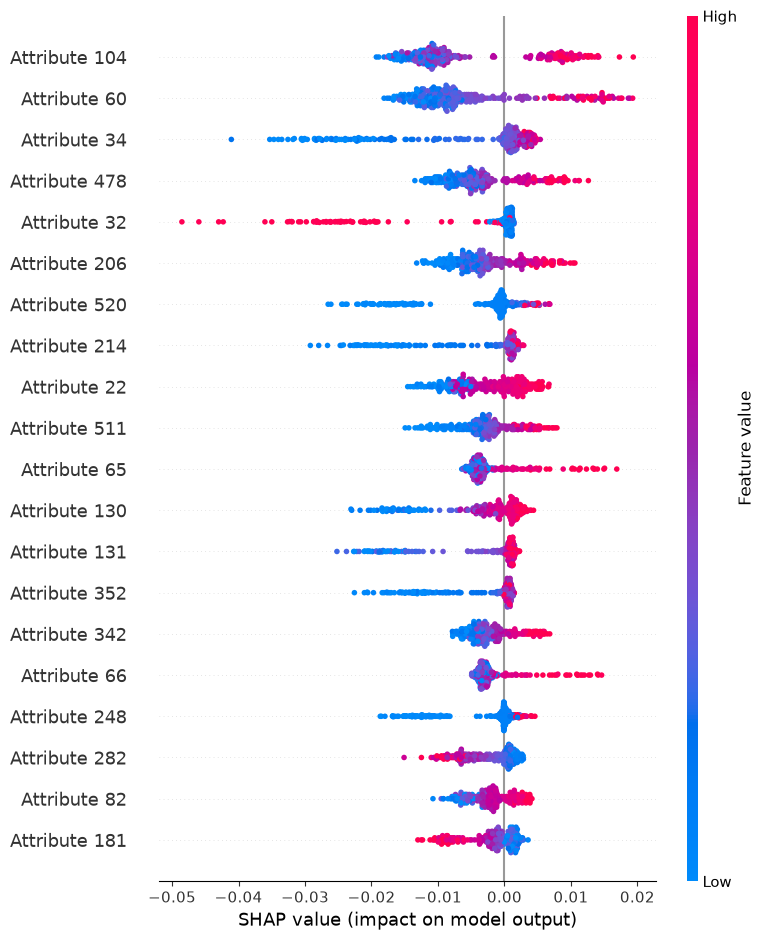

In [140]:
shap.summary_plot(
    shap_fail,
    X_test_final,
    feature_names=X_train.columns
)

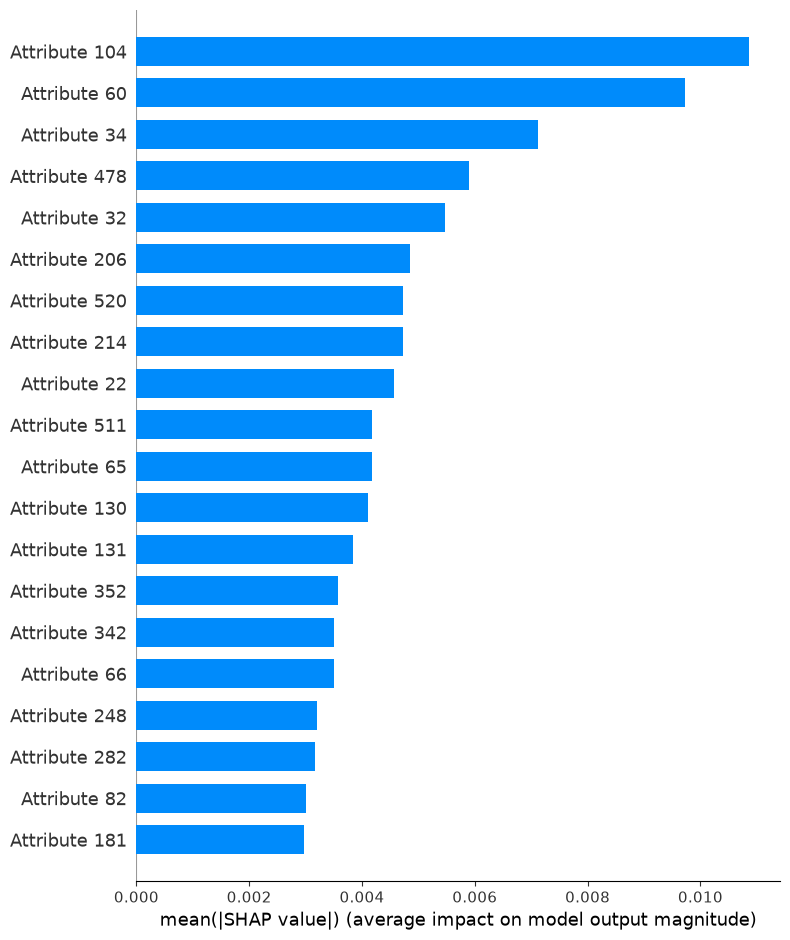

In [141]:
shap.summary_plot(
    shap_fail,
    X_test_final,
    feature_names=X_train.columns,
    plot_type="bar"
)

In [142]:
shap_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Mean_ABS_SHAP": np.abs(shap_fail).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_ABS_SHAP",
    ascending=False
)

shap_importance.head(20)

,Feature,Mean_ABS_SHAP
93,Attribute 104,0.010867
54,Attribute 60,0.009719
31,Attribute 34,0.007116
367,Attribute 478,0.005888
29,Attribute 32,0.005478
179,Attribute 206,0.004853
390,Attribute 520,0.004728
187,Attribute 214,0.004728
19,Attribute 22,0.004572
388,Attribute 511,0.004183


In [143]:
y_test_array = y_test.to_numpy()

correct_fail_positions = np.where(
    (y_test_array == 1) &
    (final_rf_pred == 1)
)[0]

print("Correctly detected FAIL positions:")
print(correct_fail_positions)

print("\nNumber detected:")
print(len(correct_fail_positions))

Correctly detected FAIL positions:
[ 60  82  88 110 181 184 185 187 239 249 276]

Number detected:
11


In [144]:
sample_position = correct_fail_positions[0]

print("Test position:", sample_position)
print("Actual class:", y_test_array[sample_position])
print("Predicted class:", final_rf_pred[sample_position])
print(
    "FAIL probability:",
    test_fail_probability[sample_position]
)

Test position: 60
Actual class: 1
Predicted class: 1
FAIL probability: 0.1325479400159879


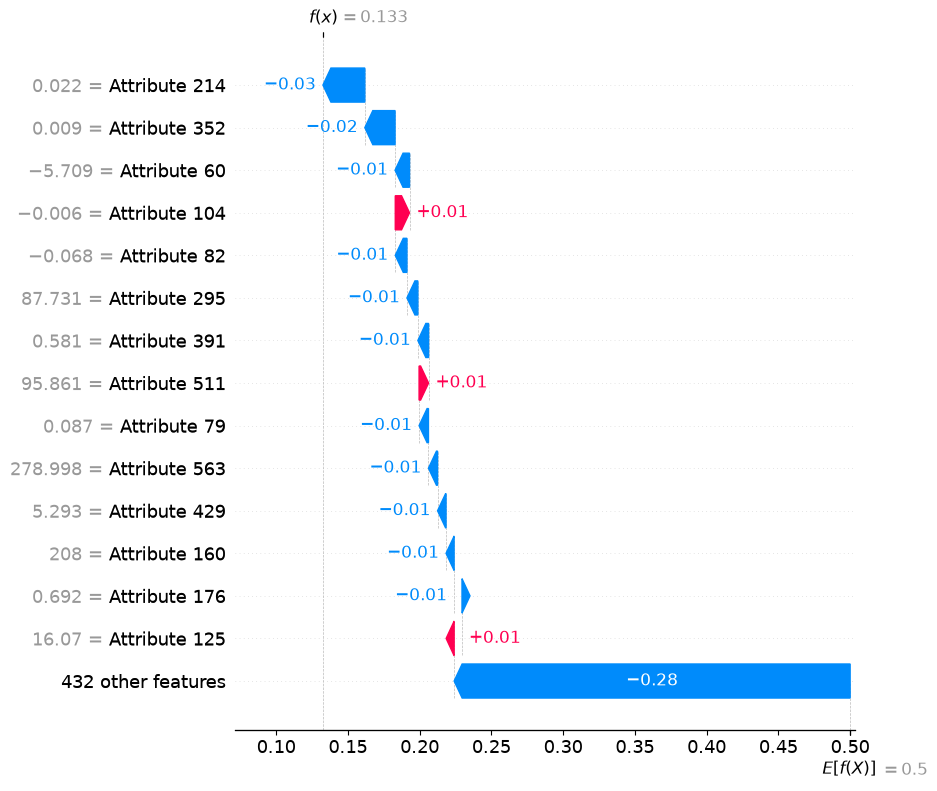

In [145]:
sample_explanation = shap.Explanation(
    values=shap_fail[sample_position],
    base_values=explainer.expected_value[fail_class_index],
    data=X_test_final[sample_position],
    feature_names=X_train.columns.tolist()
)

shap.plots.waterfall(
    sample_explanation,
    max_display=15
)

In [146]:
sample_shap_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Feature_Value": X_test_final[sample_position],
    "SHAP_Value": shap_fail[sample_position]
})

sample_shap_df["ABS_SHAP"] = np.abs(
    sample_shap_df["SHAP_Value"]
)

sample_shap_df = sample_shap_df.sort_values(
    "ABS_SHAP",
    ascending=False
)

sample_shap_df.head(10)

,Feature,Feature_Value,SHAP_Value,ABS_SHAP
187,Attribute 214,0.0219,-0.029201,0.029201
280,Attribute 352,0.0091,-0.021074,0.021074
54,Attribute 60,-5.7091,-0.010077,0.010077
93,Attribute 104,-0.0057,0.009933,0.009933
73,Attribute 82,-0.0681,-0.008140,0.008140
235,Attribute 295,87.7306,-0.007602,0.007602
303,Attribute 391,0.5814,-0.007480,0.007480
388,Attribute 511,95.8606,0.006626,0.006626
70,Attribute 79,0.0869,-0.006538,0.006538
422,Attribute 563,278.9980,-0.006338,0.006338


In [147]:
sample_shap_df.head(10)

,Feature,Feature_Value,SHAP_Value,ABS_SHAP
187,Attribute 214,0.0219,-0.029201,0.029201
280,Attribute 352,0.0091,-0.021074,0.021074
54,Attribute 60,-5.7091,-0.010077,0.010077
93,Attribute 104,-0.0057,0.009933,0.009933
73,Attribute 82,-0.0681,-0.008140,0.008140
235,Attribute 295,87.7306,-0.007602,0.007602
303,Attribute 391,0.5814,-0.007480,0.007480
388,Attribute 511,95.8606,0.006626,0.006626
70,Attribute 79,0.0869,-0.006538,0.006538
422,Attribute 563,278.9980,-0.006338,0.006338


In [148]:
sample_shap_df["Direction"] = np.where(
    sample_shap_df["SHAP_Value"] > 0,
    "Toward FAIL",
    "Toward PASS"
)

sample_shap_df.head(10)

,Feature,Feature_Value,SHAP_Value,ABS_SHAP,Direction
187,Attribute 214,0.0219,-0.029201,0.029201,Toward PASS
280,Attribute 352,0.0091,-0.021074,0.021074,Toward PASS
54,Attribute 60,-5.7091,-0.010077,0.010077,Toward PASS
93,Attribute 104,-0.0057,0.009933,0.009933,Toward FAIL
73,Attribute 82,-0.0681,-0.008140,0.008140,Toward PASS
235,Attribute 295,87.7306,-0.007602,0.007602,Toward PASS
303,Attribute 391,0.5814,-0.007480,0.007480,Toward PASS
388,Attribute 511,95.8606,0.006626,0.006626,Toward FAIL
70,Attribute 79,0.0869,-0.006538,0.006538,Toward PASS
422,Attribute 563,278.9980,-0.006338,0.006338,Toward PASS


In [149]:
toward_fail = sample_shap_df[
    sample_shap_df["SHAP_Value"] > 0
].sort_values(
    "SHAP_Value",
    ascending=False
)

toward_fail.head(10)

,Feature,Feature_Value,SHAP_Value,ABS_SHAP,Direction
93,Attribute 104,-0.0057,0.009933,0.009933,Toward FAIL
388,Attribute 511,95.8606,0.006626,0.006626,Toward FAIL
111,Attribute 125,16.0700,0.005483,0.005483,Toward FAIL
433,Attribute 574,0.1416,0.003550,0.003550,Toward FAIL
119,Attribute 133,2.1996,0.003414,0.003414,Toward FAIL
108,Attribute 122,16.0300,0.003330,0.003330,Toward FAIL
161,Attribute 181,15.8300,0.002857,0.002857,Toward FAIL
19,Attribute 22,-5333.0000,0.002639,0.002639,Toward FAIL
31,Attribute 34,8.8105,0.002562,0.002562,Toward FAIL
92,Attribute 103,-0.0597,0.002523,0.002523,Toward FAIL


In [150]:
toward_pass = sample_shap_df[
    sample_shap_df["SHAP_Value"] < 0
].sort_values(
    "SHAP_Value",
    ascending=True
)

toward_pass.head(10)

,Feature,Feature_Value,SHAP_Value,ABS_SHAP,Direction
187,Attribute 214,0.0219,-0.029201,0.029201,Toward PASS
280,Attribute 352,0.0091,-0.021074,0.021074,Toward PASS
54,Attribute 60,-5.7091,-0.010077,0.010077,Toward PASS
73,Attribute 82,-0.0681,-0.008140,0.008140,Toward PASS
235,Attribute 295,87.7306,-0.007602,0.007602,Toward PASS
303,Attribute 391,0.5814,-0.007480,0.007480,Toward PASS
70,Attribute 79,0.0869,-0.006538,0.006538,Toward PASS
422,Attribute 563,278.9980,-0.006338,0.006338,Toward PASS
328,Attribute 429,5.2930,-0.005918,0.005918,Toward PASS
142,Attribute 160,208.0000,-0.005610,0.005610,Toward PASS


In [151]:
base_fail = explainer.expected_value[fail_class_index]

total_shap_effect = shap_fail[
    sample_position
].sum()

reconstructed_output = (
    base_fail + total_shap_effect
)

print("Base FAIL output:", base_fail)
print("Combined SHAP effect:", total_shap_effect)
print("Reconstructed model output:", reconstructed_output)
print("Random Forest FAIL probability:",
      test_fail_probability[sample_position])

Base FAIL output: 0.5000000000000004
Combined SHAP effect: -0.3674520600093234
Reconstructed model output: 0.13254793999067704
Random Forest FAIL probability: 0.1325479400159879


In [152]:
normal_mask = y_subtrain == -1

X_normal_train = X_subtrain.loc[normal_mask]

print("Normal PASS samples used for training:")
print(X_normal_train.shape)

Normal PASS samples used for training:
(936, 446)


In [153]:
from sklearn.impute import SimpleImputer

anomaly_imputer = SimpleImputer(strategy="median")

X_normal_train_imputed = anomaly_imputer.fit_transform(
    X_normal_train
)

X_val_anomaly = anomaly_imputer.transform(
    X_val
)

print("Normal training shape:",
      X_normal_train_imputed.shape)

print("Validation shape:",
      X_val_anomaly.shape)

Normal training shape: (936, 446)
Validation shape: (251, 446)


In [154]:
from sklearn.ensemble import IsolationForest

iso_model = IsolationForest(
    n_estimators=500,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

iso_model.fit(
    X_normal_train_imputed
)

print("Isolation Forest trained!")

Isolation Forest trained!


In [155]:
val_anomaly_score = -iso_model.score_samples(
    X_val_anomaly
)

print("Lowest anomaly score:",
      val_anomaly_score.min())

print("Highest anomaly score:",
      val_anomaly_score.max())

print("Average anomaly score:",
      val_anomaly_score.mean())

Lowest anomaly score: 0.37305870635630123
Highest anomaly score: 0.48027760516952134
Average anomaly score: 0.40088975231544083


In [156]:
val_anomaly_df = pd.DataFrame({
    "Anomaly_Score": val_anomaly_score,
    "Actual_Class": y_val.to_numpy()
})

val_anomaly_df["Status"] = val_anomaly_df[
    "Actual_Class"
].map({
    -1: "PASS",
     1: "FAIL"
})

val_anomaly_df.groupby("Status")[
    "Anomaly_Score"
].describe()

,count,mean,std,min,25%,50%,75%,max
Status,,,,,,,,
FAIL,17.0,0.406434,0.018658,0.381780,0.392488,0.404281,0.417623,0.456894
PASS,234.0,0.400487,0.015464,0.373059,0.389509,0.398151,0.408717,0.480278


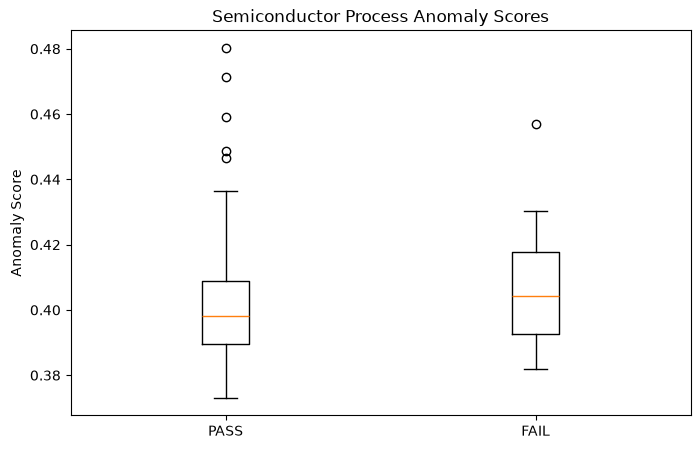

In [162]:
import matplotlib.pyplot as plt

pass_scores = val_anomaly_df[
    val_anomaly_df["Status"] == "PASS"
]["Anomaly_Score"]

fail_scores = val_anomaly_df[
    val_anomaly_df["Status"] == "FAIL"
]["Anomaly_Score"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [pass_scores, fail_scores],
    tick_labels=["PASS", "FAIL"]
)

plt.ylabel("Anomaly Score")
plt.title("Semiconductor Process Anomaly Scores")

plt.show()

In [163]:
y_val_anomaly_binary = (
    y_val == 1
).astype(int)

In [164]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

iso_roc_auc = roc_auc_score(
    y_val_anomaly_binary,
    val_anomaly_score
)

iso_pr_auc = average_precision_score(
    y_val_anomaly_binary,
    val_anomaly_score
)

print(f"Isolation Forest ROC-AUC: {iso_roc_auc:.3f}")
print(f"Isolation Forest PR-AUC:  {iso_pr_auc:.3f}")

Isolation Forest ROC-AUC: 0.597
Isolation Forest PR-AUC:  0.115


In [165]:
anomaly_threshold_results = []

thresholds = np.linspace(
    val_anomaly_score.min(),
    val_anomaly_score.max(),
    50
)

for threshold in thresholds:

    # 1 = anomaly / potential FAIL
    # 0 = normal
    predictions = (
        val_anomaly_score >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_anomaly_binary,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_anomaly_binary,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val_anomaly_binary,
        predictions,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val_anomaly_binary,
        predictions,
        beta=2,
        zero_division=0
    )

    cm = confusion_matrix(
        y_val_anomaly_binary,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    anomaly_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "F2": f2,
        "False Alarms": fp,
        "Missed FAIL": fn,
        "Detected FAIL": tp
    })

anomaly_threshold_df = pd.DataFrame(
    anomaly_threshold_results
)

In [166]:
anomaly_candidates = anomaly_threshold_df[
    anomaly_threshold_df["Recall"] >= 0.40
]

anomaly_candidates.sort_values(
    "False Alarms",
    ascending=True
).head(15)

,Threshold,Precision,Recall,F1,F2,False Alarms,Missed FAIL,Detected FAIL
16,0.408069,0.102941,0.411765,0.164706,0.257353,61,10,7
15,0.405881,0.095238,0.470588,0.158416,0.263158,76,9,8
14,0.403693,0.094737,0.529412,0.160714,0.276074,86,8,9
13,0.401505,0.097087,0.588235,0.166667,0.292398,93,7,10
12,0.399316,0.084746,0.588235,0.148148,0.268817,108,7,10
11,0.397128,0.073529,0.588235,0.130719,0.245098,126,7,10
10,0.394940,0.080000,0.705882,0.143713,0.275229,138,5,12
9,0.392752,0.074074,0.705882,0.134078,0.260870,150,5,12
8,0.390564,0.077348,0.823529,0.141414,0.281124,167,3,14
7,0.388376,0.071795,0.823529,0.132075,0.266160,181,3,14


In [167]:
best_anomaly_threshold = 0.408069

In [168]:
X_test_anomaly = anomaly_imputer.transform(X_test)

In [169]:
test_anomaly_score = -iso_model.score_samples(
    X_test_anomaly
)

print("Minimum:", test_anomaly_score.min())
print("Maximum:", test_anomaly_score.max())
print("Average:", test_anomaly_score.mean())

Minimum: 0.371237103585543
Maximum: 0.4665572631816308
Average: 0.40247945238006677


In [170]:
best_anomaly_threshold = 0.408069

final_anomaly_pred = (
    test_anomaly_score >= best_anomaly_threshold
).astype(int)

In [171]:
y_test_anomaly_binary = (
    y_test == 1
).astype(int)

In [172]:
iso_test_cm = confusion_matrix(
    y_test_anomaly_binary,
    final_anomaly_pred,
    labels=[0, 1]
)

tn_iso, fp_iso, fn_iso, tp_iso = iso_test_cm.ravel()

print("Normal PASS:", tn_iso)
print("False alarms:", fp_iso)
print("Missed FAIL:", fn_iso)
print("Detected FAIL:", tp_iso)

Normal PASS: 206
False alarms: 87
Missed FAIL: 10
Detected FAIL: 11


In [173]:
iso_accuracy = accuracy_score(
    y_test_anomaly_binary,
    final_anomaly_pred
)

iso_precision = precision_score(
    y_test_anomaly_binary,
    final_anomaly_pred,
    zero_division=0
)

iso_recall = recall_score(
    y_test_anomaly_binary,
    final_anomaly_pred,
    zero_division=0
)

iso_f1 = f1_score(
    y_test_anomaly_binary,
    final_anomaly_pred,
    zero_division=0
)

iso_test_roc_auc = roc_auc_score(
    y_test_anomaly_binary,
    test_anomaly_score
)

iso_test_pr_auc = average_precision_score(
    y_test_anomaly_binary,
    test_anomaly_score
)

In [174]:
print("=" * 60)
print("SEMICONDUCTOR PROCESS ANOMALY DETECTION")
print("=" * 60)

print(f"Anomaly threshold:    {best_anomaly_threshold:.6f}")

print()
print(f"Accuracy:             {iso_accuracy:.3f}")
print(f"FAIL Precision:       {iso_precision:.3f}")
print(f"FAIL Recall:          {iso_recall:.3f}")
print(f"FAIL F1-score:        {iso_f1:.3f}")
print(f"ROC-AUC:              {iso_test_roc_auc:.3f}")
print(f"PR-AUC:               {iso_test_pr_auc:.3f}")

print()
print(f"Normal PASS:          {tn_iso}")
print(f"False alarms:         {fp_iso}")
print(f"Missed FAIL:          {fn_iso}")
print(f"Detected FAIL:        {tp_iso}")
print(f"Total actual FAIL:    {fn_iso + tp_iso}")

SEMICONDUCTOR PROCESS ANOMALY DETECTION
Anomaly threshold:    0.408069

Accuracy:             0.691
FAIL Precision:       0.112
FAIL Recall:          0.524
FAIL F1-score:        0.185
ROC-AUC:              0.574
PR-AUC:               0.169

Normal PASS:          206
False alarms:         87
Missed FAIL:          10
Detected FAIL:        11
Total actual FAIL:    21


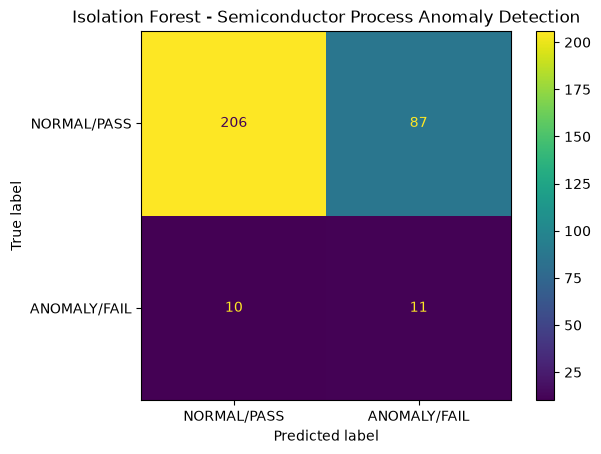

In [175]:
ConfusionMatrixDisplay(
    confusion_matrix=iso_test_cm,
    display_labels=["NORMAL/PASS", "ANOMALY/FAIL"]
).plot()

plt.title("Isolation Forest - Semiconductor Process Anomaly Detection")
plt.show()

In [176]:
%pip install streamlit joblib

  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   ------------- -------------------------- 3.7/10.5 MB 19.9 MB/s eta 0:00:01
   ----------------------------------- ---- 9.4/10.5 MB 24.2 MB/s eta 0:00:01
   ---------------------------------------- 10.5/10.5 MB 22.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/797.6 kB ? eta -:--:--
   --------------------------------------- 797.6/797.6 kB 14.6 MB/s eta 0:00:00
Using cached blinker-1.9.0-py3-none-any.whl (8.5 kB)
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
   ---------------------------------------- 0.0/27.9 MB ? eta -:--:--
   ------- -------------------------------- 5.2/27.9 MB 25.6 MB/s eta 0:00:01
   --------------- ------------------------ 10.7/27.9 MB 25.9 MB/s eta 0:00:01
   ------------------------- -------------- 17.8/27.9 MB 28.8 MB/s eta 0:0


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [177]:
import os
import joblib

os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

In [178]:
joblib.dump(
    final_rf_model,
    "models/random_forest.pkl"
)

joblib.dump(
    final_rf_imputer,
    "models/rf_imputer.pkl"
)

['models/rf_imputer.pkl']

In [179]:
joblib.dump(
    iso_model,
    "models/isolation_forest.pkl"
)

joblib.dump(
    anomaly_imputer,
    "models/anomaly_imputer.pkl"
)

['models/anomaly_imputer.pkl']

In [180]:
joblib.dump(
    X_train.columns.tolist(),
    "models/feature_names.pkl"
)

['models/feature_names.pkl']

In [181]:
thresholds = {
    "rf_threshold": 0.10,
    "anomaly_threshold": 0.408069
}

joblib.dump(
    thresholds,
    "models/thresholds.pkl"
)

['models/thresholds.pkl']

In [182]:
demo_data = X_test.copy()

demo_data["Actual_Class"] = y_test.values

demo_data = demo_data.reset_index(drop=True)

demo_data.to_csv(
    "data/demo_samples.csv",
    index=False
)

print(demo_data.shape)

(314, 447)
